In [9]:
import pytorch_lightning as pl
import mlflow
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

In [10]:
emnist_test_data = pd.read_csv("emnist-letters-test.csv")

emnist_test_data = emnist_test_data.sample(frac = 1) #shuffles the data

In [11]:
class EMNISTDataset(Dataset):
  def __init__(self, dataframe):
    self.images = torch.tensor(dataframe.iloc[:,1:].values, dtype=torch.float32)
    self.labels = torch.tensor(dataframe.iloc[:,0].values, dtype=torch.float32)

  def __len__(self):
    return len(self.images)

  def __getitem__(self, idx):
    images = self.images[idx]
    images = images/255.0
    labels = self.labels[idx]

    return images, labels

In [12]:
test_dataset = EMNISTDataset(emnist_test_data)

test_dataloader = DataLoader(test_dataset, batch_size=64)

In [13]:
test_dataiter = iter(test_dataloader)

test_imgs, test_labels = next(test_dataiter)

test_imgs.shape, test_labels.shape

(torch.Size([64, 784]), torch.Size([64]))

In [14]:
class EmnistModel(pl.LightningModule):
  def forward(self, xb):
    out = self.net(xb.reshape(-1, 1, 28, 28))
    return out

In [15]:
# One-time load of your old, trusted local MLflow model
raw_model = mlflow.pytorch.load_model("./best_model")

# The outer EmnistModel.forward() is broken across Python versions,
# but its Sequential network and trained weights loaded correctly.
trained_net = raw_model.net.eval()

print(trained_net)

2026/07/21 10:48:46 WARNING mlflow.pytorch: Stored model version '2.11.0+cu128' does not match installed PyTorch version '2.5.1+cu121'


Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (3): ReLU()
  (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (6): ReLU()
  (7): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (8): ReLU()
  (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (10): Flatten(start_dim=1, end_dim=-1)
  (11): Linear(in_features=12544, out_features=64, bias=True)
  (12): ReLU()
  (13): Linear(in_features=64, out_features=64, bias=True)
  (14): ReLU()
  (15): Linear(in_features=64, out_features=26, bias=True)
)


In [17]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

trained_net = trained_net.to(device)

x = torch.as_tensor(
    test_imgs[:16].numpy().reshape(-1, 1, 28, 28),
    dtype=torch.float32,
    device=device,
)

#like torch.no_grad() but more optimized and stricter
with torch.inference_mode():
    logits = trained_net(x)

print(logits.shape)
print(logits.device)

torch.Size([16, 26])
cuda:0


In [18]:
from torch import nn
def build_emnist_model():
    return nn.Sequential(
        nn.Conv2d(1, 32, kernel_size=3, padding=1),
        nn.ReLU(),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),

        nn.MaxPool2d(kernel_size=2),

        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.ReLU(),

        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.ReLU(),

        nn.MaxPool2d(kernel_size=2),

        nn.Flatten(start_dim=1),

        nn.Linear(256 * 7 * 7, 64),
        nn.ReLU(),

        nn.Linear(64, 64),
        nn.ReLU(),

        nn.Linear(64, 26),
    )

In [7]:
from mlflow.models import ModelSignature
from mlflow.types import Schema, TensorSpec


signature = ModelSignature(
    inputs=Schema([
        TensorSpec(
            np.dtype(np.float32),
            (-1, 1, 28, 28),
        )
    ]),
    outputs=Schema([
        TensorSpec(
            np.dtype(np.float32),
            (-1, 26),
        )
    ]),
)

print(signature)

inputs: 
  [Tensor('float32', (-1, 1, 28, 28))]
outputs: 
  [Tensor('float32', (-1, 26))]
params: 
  None



In [21]:
#logs the trained_net sequential to safetensors in a new run in MLFLOW
import copy
from pathlib import Path
from tempfile import TemporaryDirectory

import mlflow
import torch

from safetensors.torch import save_model

mlflow.set_tracking_uri("http://127.0.0.1:5001")
mlflow.set_experiment("EMNIST")

with mlflow.start_run(run_name="emnist-cnn-safetensors") as run:
    run_id = run.info.run_id

    with TemporaryDirectory() as temp_dir:
        weights_path = Path(temp_dir) / "model.safetensors"

        # Preserve the live GPU model; serialize a temporary CPU copy.
        model_for_saving = copy.deepcopy(trained_net).cpu().eval()

        save_model(
            model_for_saving,
            str(weights_path),
            metadata={
                "architecture": "emnist-cnn-v1",
                "input_shape": "[-1, 1, 28, 28]",
                "output_shape": "[-1, 26]",
            },
        )

        mlflow.log_artifact(
            str(weights_path),
            artifact_path="model",
        )

    # Store the manually written signature as metadata.
    mlflow.log_dict(
        signature.to_dict(),
        "model/signature.json",
    )

    mlflow.log_dict(
        {
            "architecture": "emnist-cnn-v1",
            "input_shape": [-1, 1, 28, 28],
            "output_shape": [-1, 26],
            "num_classes": 26,
            "weights_format": "safetensors",
            "torch_version": torch.__version__,
        },
        "model/config.json",
    )

print("Run ID:", run_id)

🏃 View run emnist-cnn-safetensors at: http://127.0.0.1:5001/#/experiments/1/runs/f5b09dac39d542f085e3b34947956327
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Run ID: f5b09dac39d542f085e3b34947956327


In [22]:
#verify we can load the model as safetensors
import mlflow
import torch

from safetensors.torch import load_model


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights_path = mlflow.artifacts.download_artifacts(
    artifact_uri=f"runs:/{run_id}/model/model.safetensors"
)

loaded_model = build_emnist_model().to(device)

missing, unexpected = load_model(
    loaded_model,
    weights_path,
    strict=True,
    device=str(device),
)

loaded_model.eval()

print("Device:", next(loaded_model.parameters()).device)
print("Missing:", missing)
print("Unexpected:", unexpected)

Device: cuda:0
Missing: set()
Unexpected: []


In [24]:
#use the model to do inference
x = torch.as_tensor(
    test_imgs[:16].numpy().reshape(-1, 1, 28, 28),
    dtype=torch.float32,
    device=device,
)

with torch.inference_mode():
    loaded_logits = loaded_model(x)
    predictions = loaded_logits.argmax(dim=1)

print("Logits:", loaded_logits.shape)
print("Predictions:", predictions.shape)
print("Device:", loaded_logits.device)

Logits: torch.Size([16, 26])
Predictions: torch.Size([16])
Device: cuda:0


prediction:  q


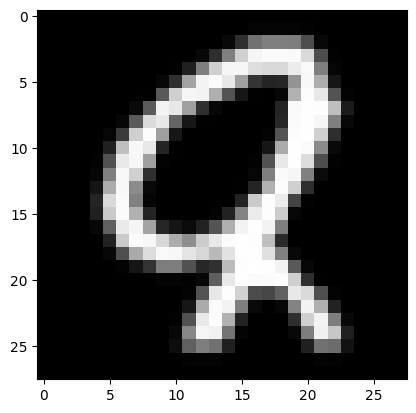

In [48]:
classes = list('abcdefghijklmnopqrstuvwxyz')

prediction = classes[predictions[2].item()]
print('prediction: ', prediction)
    
plt.imshow(test_imgs[2].numpy().reshape(28, 28).transpose(), cmap='grey')

In [38]:
%%writefile emnist_safetensors_model.py

#wrapper code to run inference on the safetensors model when serving in MLFLOW
import numpy as np
import torch
from torch import nn

from mlflow.models import set_model
from mlflow.pyfunc import PythonModel
from safetensors.torch import load_model


def build_emnist_model():
    return nn.Sequential(
        nn.Conv2d(1, 32, 3, padding=1),
        nn.ReLU(),

        nn.Conv2d(32, 64, 3, padding=1),
        nn.ReLU(),

        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, 3, padding=1),
        nn.ReLU(),

        nn.Conv2d(128, 256, 3, padding=1),
        nn.ReLU(),

        nn.MaxPool2d(2),

        nn.Flatten(start_dim=1),

        nn.Linear(256 * 7 * 7, 64),
        nn.ReLU(),

        nn.Linear(64, 64),
        nn.ReLU(),

        nn.Linear(64, 26),
    )


class EmnistSafetensorsModel(PythonModel):

    def load_context(self, context):
        self.device = torch.device(
            "cuda" if torch.cuda.is_available() else "cpu"
        )

        self.model = build_emnist_model()

        load_model(
            self.model,
            context.artifacts["weights"],
            strict=True,
            device="cpu",
        )

        self.model = self.model.to(self.device)
        self.model.eval()

    def predict(self, context, model_input, params=None):
        if hasattr(model_input, "to_numpy"):
            model_input = model_input.to_numpy()

        array = np.asarray(model_input, dtype=np.float32)

        if array.ndim == 3:
            array = array[:, None, :, :]

        if array.ndim != 4 or tuple(array.shape[1:]) != (1, 28, 28):
            raise ValueError(
                "Expected shape (batch, 1, 28, 28), "
                f"received {array.shape}"
            )

        tensor = torch.from_numpy(array).to(self.device)

        with torch.inference_mode():
            logits = self.model(tensor)

        return logits.cpu().numpy()

# identifies the specific object that represents the model
set_model(EmnistSafetensorsModel())

Writing emnist_safetensors_model.py


In [40]:
import mlflow


weights_path = (
    r"<home>\Jupyter_AI\mlflow\mlartifacts\1"
    r"\ea8209aafee5432cadf5e8f4d9a6ba97"
    r"\artifacts\model\model.safetensors"
)

wrapper_path = (
    r"<home>\Jupyter_AI\mlflow"
    r"\emnist_safetensors_model.py"
)


mlflow.set_tracking_uri("http://127.0.0.1:5001")
mlflow.set_experiment("EMNIST")

with mlflow.start_run(run_name="emnist-safetensors-serving") as run:
    model_info = mlflow.pyfunc.log_model(
        name="model",
        python_model=wrapper_path,
        artifacts={
            "weights": weights_path,
        },
        signature=signature,
    )

    run_id = run.info.run_id
    model_uri = model_info.model_uri


print("Run ID:", run_id)
print("Model URI:", model_uri)

C:\pinokio\bin\miniconda\envs\micrograd\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
C:\pinokio\bin\miniconda\envs\micrograd\Lib\site-packages\mlflow\pyfunc\__init__.py:3341: UserWarning: An input example was not provided when logging the model. To ensure the model signature functions correctly, specify the `input_example` parameter. See https://mlflow.org/docs/latest/model/signatures.html#model-input-example for more details about the benefits of using input_example.
  color_warning(


2026/07/21 11:27:45 WARNING mlflow.utils.requirements_utils: Found torch version (2.5.1+cu121) contains a local version label (+cu121). MLflow logged a pip requirement for this package as 'torch==2.5.1' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.


🏃 View run emnist-safetensors-serving at: http://127.0.0.1:5001/#/experiments/1/runs/3e8344b5bfcb474b90923bbe7db73726
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
Run ID: 3e8344b5bfcb474b90923bbe7db73726
Model URI: models:/m-53450ecc46a244e4bffba253ca52c33e


In [41]:
import mlflow.pyfunc

model_uri = "models:/m-53450ecc46a244e4bffba253ca52c33e"

loaded_model = mlflow.pyfunc.load_model(model_uri)

print("Model loaded successfully")

Model loaded successfully


C:\pinokio\bin\miniconda\envs\micrograd\Lib\site-packages\mlflow\pyfunc\utils\data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [44]:
import numpy as np

x = np.asarray(test_imgs[:16].numpy().reshape(-1, 1, 28, 28), dtype=np.float32)

# Ensure the signature-required shape: (batch, channel, height, width)
if x.ndim == 3:
    x = x[:, None, :, :]

logits = loaded_model.predict(x)
predictions = logits.argmax(axis=1)

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Predictions:", predictions)

Input shape: (16, 1, 28, 28)
Output shape: (16, 26)
Predictions: [10  2 16  0  2 11  5  8 15 13  7 11  0  1  4 16]


In [46]:
import requests
import numpy as np

x = np.asarray(test_imgs[:4].numpy().reshape(-1, 1, 28, 28), dtype=np.float32)

if x.ndim == 3:
    x = x[:, None, :, :]

response = requests.post(
    "http://127.0.0.1:1234/invocations",
    json={"inputs": x.tolist()},
    timeout=30,
)

print("Status:", response.status_code)
print(response.text[:500])

result = response.json()

logits = np.asarray(result["predictions"])
predictions = logits.argmax(axis=1)

print("Logits shape:", logits.shape)
print("Predicted class indices:", predictions)

Status: 200
{"predictions": [[-4.932871341705322, -1.9828511476516724, -8.694021224975586, -6.456038475036621, -5.923289775848389, -5.947983264923096, -4.363749980926514, 3.417191982269287, -10.659331321716309, -9.517607688903809, 14.531793594360352, -2.7073285579681396, -6.297122955322266, -4.556826591491699, -26.385602951049805, -11.35429573059082, -7.841547966003418, 2.948700189590454, -13.250199317932129, -0.559609055519104, -2.6430938243865967, -9.532759666442871, -4.362894535064697, 4.493227481842041,
Logits shape: (4, 26)
Predicted class indices: [10  2 16  0]


"hey hey you you I don't like your boyfriend"